In [1]:
import os, json, time, pickle
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

BASE   = r'D:\FYP\Eco-Twin'
V2_DIR = os.path.join(BASE, 'v2_clean')
OUT    = os.path.join(V2_DIR, 'ecotwin_outputs')
DATA_DIR, SCALER_DIR = os.path.join(OUT,'data'), os.path.join(OUT,'scalers')
PLOT_DIR, MODEL_DIR, RESULTS_DIR = os.path.join(OUT,'plots'), os.path.join(OUT,'models'), os.path.join(OUT,'results')

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {DEVICE}")

X_train  = np.load(os.path.join(DATA_DIR,'X_train.npy'))
Y_train  = np.load(os.path.join(DATA_DIR,'Y_train.npy'))
At_train = np.load(os.path.join(DATA_DIR,'At_train.npy'))
X_val    = np.load(os.path.join(DATA_DIR,'X_val.npy'))
Y_val    = np.load(os.path.join(DATA_DIR,'Y_val.npy'))
At_val   = np.load(os.path.join(DATA_DIR,'At_val.npy'))
X_test   = np.load(os.path.join(DATA_DIR,'X_test.npy'))
Y_test   = np.load(os.path.join(DATA_DIR,'Y_test.npy'))
At_test  = np.load(os.path.join(DATA_DIR,'At_test.npy'))

with open(os.path.join(SCALER_DIR,'pm25_scaler.pkl'),'rb') as f:
    pm25_scaler = pickle.load(f)

N = X_train.shape[2]
F = X_train.shape[3]
print(f"Train {X_train.shape} | Val {X_val.shape} | Test {X_test.shape}")
print(f"N={N} stations, F={F} features")

Device: cuda
Train (13873, 48, 37, 14) | Val (2917, 48, 37, 14) | Test (2918, 48, 37, 14)
N=37 stations, F=14 features


In [2]:
class WindowDataset(Dataset):
    def __init__(self, X, Y, At):
        self.X, self.Y, self.At = X, Y, At
    def __len__(self):
        return self.X.shape[0]
    def __getitem__(self, i):
        return (torch.from_numpy(self.X[i]).float(),
                torch.from_numpy(self.At[i]).float(),
                torch.from_numpy(self.Y[i]).float())

BATCH_SIZE = 16
train_ds = WindowDataset(X_train, Y_train, At_train)
val_ds   = WindowDataset(X_val,   Y_val,   At_val)
test_ds  = WindowDataset(X_test,  Y_test,  At_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Batch {BATCH_SIZE} | train {len(train_loader)} | val {len(val_loader)} | test {len(test_loader)} batches")

Batch 16 | train 868 | val 183 | test 183 batches


In [3]:
class WATGCN(nn.Module):
    def __init__(self, in_features, hidden_dim, gru_layers, attn_heads,
                 forecast_horizon, n_stations, dropout=0.2):
        super().__init__()
        self.input_proj  = nn.Linear(in_features, hidden_dim)
        self.gcn_linear  = nn.Linear(hidden_dim, hidden_dim)
        self.gcn_norm    = nn.LayerNorm(hidden_dim)
        self.act         = nn.ReLU()
        self.gru         = nn.GRU(hidden_dim, hidden_dim, gru_layers,
                                  batch_first=True,
                                  dropout=dropout if gru_layers > 1 else 0)
        self.attention   = nn.MultiheadAttention(hidden_dim, attn_heads,
                                                 dropout=dropout, batch_first=True)
        self.attn_norm   = nn.LayerNorm(hidden_dim)
        self.dropout     = nn.Dropout(dropout)
        self.output_proj = nn.Linear(hidden_dim, forecast_horizon)
        self.H, self.FH  = hidden_dim, forecast_horizon

    def forward(self, X, At):
        B, T, N, F = X.shape
        H = self.act(self.input_proj(X))

        # self-loops so each station keeps its own signal
        I = torch.eye(N, device=At.device).unsqueeze(0).unsqueeze(0)
        A = At + I
        A = A / A.sum(dim=-1, keepdim=True).clamp(min=1e-6)

        H_agg = torch.matmul(A, H)
        H_agg = self.act(self.gcn_norm(self.gcn_linear(H_agg)))
        H_agg = H_agg + H                                   # residual

        H_flat = H_agg.permute(0,2,1,3).reshape(B*N, T, self.H)
        g, _ = self.gru(H_flat)
        g = self.dropout(g)
        a, _ = self.attention(g, g, g)
        a = self.attn_norm(a + g)
        out = self.output_proj(a[:, -1, :])
        return out.reshape(B, N, self.FH).permute(0, 2, 1)

hparams = dict(in_features=F, hidden_dim=64, gru_layers=2, attn_heads=4,
               forecast_horizon=24, n_stations=N, dropout=0.2)

model = WATGCN(**hparams).to(DEVICE)
with open(os.path.join(MODEL_DIR,'hparams.json'),'w') as f:
    json.dump(hparams, f, indent=2)

print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
for k,v in hparams.items(): print(f"  {k:<18}: {v}")

Parameters: 73,496
  in_features       : 14
  hidden_dim        : 64
  gru_layers        : 2
  attn_heads        : 4
  forecast_horizon  : 24
  n_stations        : 37
  dropout           : 0.2


In [4]:
MAX_EPOCHS, PATIENCE, LR = 60, 10, 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'min', factor=0.5, patience=4)
criterion = nn.MSELoss()

best_val, patience_ctr = float('inf'), 0
history = {'train_loss':[], 'val_loss':[], 'lr':[]}
ckpt = os.path.join(MODEL_DIR,'watgcn_best.pt')

print(f"{'Ep':>3} | {'Train':>10} | {'Val':>10} | {'LR':>8} | {'Time':>6} | Status")
print("-"*62)

for ep in range(1, MAX_EPOCHS+1):
    t0 = time.time()
    model.train(); tr = 0.0
    for Xb, Ab, Yb in train_loader:
        Xb, Ab, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(Xb, Ab), Yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        tr += loss.item() * Xb.size(0)
    tr /= len(train_ds)

    model.eval(); vl = 0.0
    with torch.no_grad():
        for Xb, Ab, Yb in val_loader:
            Xb, Ab, Yb = Xb.to(DEVICE), Ab.to(DEVICE), Yb.to(DEVICE)
            vl += criterion(model(Xb, Ab), Yb).item() * Xb.size(0)
    vl /= len(val_ds)

    scheduler.step(vl)
    cur_lr = optimizer.param_groups[0]['lr']
    history['train_loss'].append(tr); history['val_loss'].append(vl); history['lr'].append(cur_lr)

    if vl < best_val:
        best_val, patience_ctr = vl, 0
        torch.save(model.state_dict(), ckpt)
        st = "best"
    else:
        patience_ctr += 1
        st = f"{patience_ctr}/{PATIENCE}"

    print(f"{ep:>3} | {tr:>10.6f} | {vl:>10.6f} | {cur_lr:>8.1e} | {time.time()-t0:>5.1f}s | {st}")

    if patience_ctr >= PATIENCE:
        print(f"\nStopped at epoch {ep}. Best val: {best_val:.6f}")
        break

with open(os.path.join(RESULTS_DIR,'training_history.json'),'w') as f:
    json.dump(history, f, indent=2)

 Ep |      Train |        Val |       LR |   Time | Status
--------------------------------------------------------------
  1 |   0.410901 |   0.434923 |  1.0e-03 |  27.3s | best
  2 |   0.331446 |   0.425223 |  1.0e-03 |  23.7s | best
  3 |   0.299448 |   0.461856 |  1.0e-03 |  23.7s | 1/10
  4 |   0.268442 |   0.430626 |  1.0e-03 |  23.7s | 2/10
  5 |   0.248967 |   0.446476 |  1.0e-03 |  23.7s | 3/10
  6 |   0.226678 |   0.462798 |  1.0e-03 |  23.8s | 4/10
  7 |   0.208274 |   0.494774 |  5.0e-04 |  22.7s | 5/10
  8 |   0.182787 |   0.463478 |  5.0e-04 |  22.6s | 6/10
  9 |   0.174586 |   0.474132 |  5.0e-04 |  23.0s | 7/10
 10 |   0.168635 |   0.467000 |  5.0e-04 |  23.0s | 8/10
 11 |   0.162891 |   0.459898 |  5.0e-04 |  22.7s | 9/10
 12 |   0.158048 |   0.456102 |  2.5e-04 |  22.5s | 10/10

Stopped at epoch 12. Best val: 0.425223


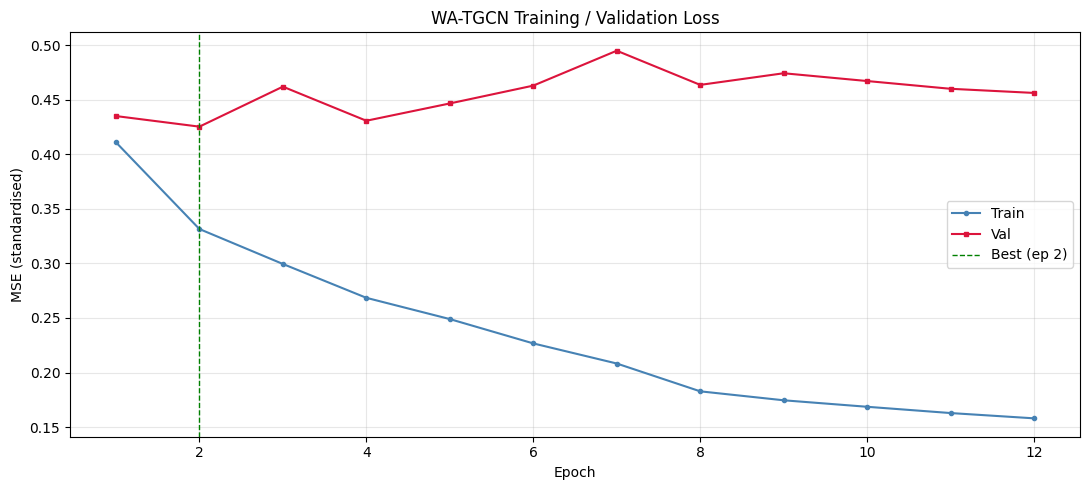

In [5]:
fig, ax = plt.subplots(figsize=(11,5))
eps = range(1, len(history['train_loss'])+1)
ax.plot(eps, history['train_loss'], marker='o', ms=3, label='Train', color='steelblue')
ax.plot(eps, history['val_loss'],   marker='s', ms=3, label='Val',   color='crimson')
best_ep = int(np.argmin(history['val_loss']))+1
ax.axvline(best_ep, color='green', ls='--', lw=1, label=f'Best (ep {best_ep})')
ax.set_xlabel('Epoch'); ax.set_ylabel('MSE (standardised)')
ax.set_title('WA-TGCN Training / Validation Loss')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR,'loss_curve.png'), dpi=150, bbox_inches='tight')
plt.show()

In [6]:
model.load_state_dict(torch.load(ckpt))
model.eval()
P, A_ = [], []
with torch.no_grad():
    for Xb, Ab, Yb in test_loader:
        P.append(model(Xb.to(DEVICE), Ab.to(DEVICE)).cpu().numpy())
        A_.append(Yb.numpy())
preds_s, actual_s = np.concatenate(P), np.concatenate(A_)
print(f"Predictions {preds_s.shape}")

Predictions (2918, 24, 37)


In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

inv = lambda a: pm25_scaler.inverse_transform(a.reshape(-1,1)).reshape(a.shape)
preds, actual = inv(preds_s), inv(actual_s)

pf, af = preds.flatten(), actual.flatten()
rmse = np.sqrt(mean_squared_error(af, pf))
mae  = mean_absolute_error(af, pf)
r2   = r2_score(af, pf)

print(f"RMSE : {rmse:.2f} µg/m³")
print(f"MAE  : {mae:.2f} µg/m³")
print(f"R²   : {r2:.4f}")
print()

# persistence baseline for context
persist = actual[:, :1, :].repeat(24, axis=1)
p_rmse  = np.sqrt(mean_squared_error(actual.flatten(), persist.flatten()))
print(f"Persistence baseline RMSE : {p_rmse:.2f}")
print(f"Model beats baseline      : {'YES' if rmse < p_rmse else 'NO'}")
print()
print("RMSE by forecast hour:")
for h in [0,5,11,17,23]:
    print(f"  +{h+1:>2}h : {np.sqrt(mean_squared_error(actual[:,h,:].flatten(), preds[:,h,:].flatten())):.2f}")

RMSE : 65.58 µg/m³
MAE  : 46.33 µg/m³
R²   : 0.5759

Persistence baseline RMSE : 82.39
Model beats baseline      : YES

RMSE by forecast hour:
  + 1h : 39.05
  + 6h : 68.24
  +12h : 68.46
  +18h : 68.03
  +24h : 67.81


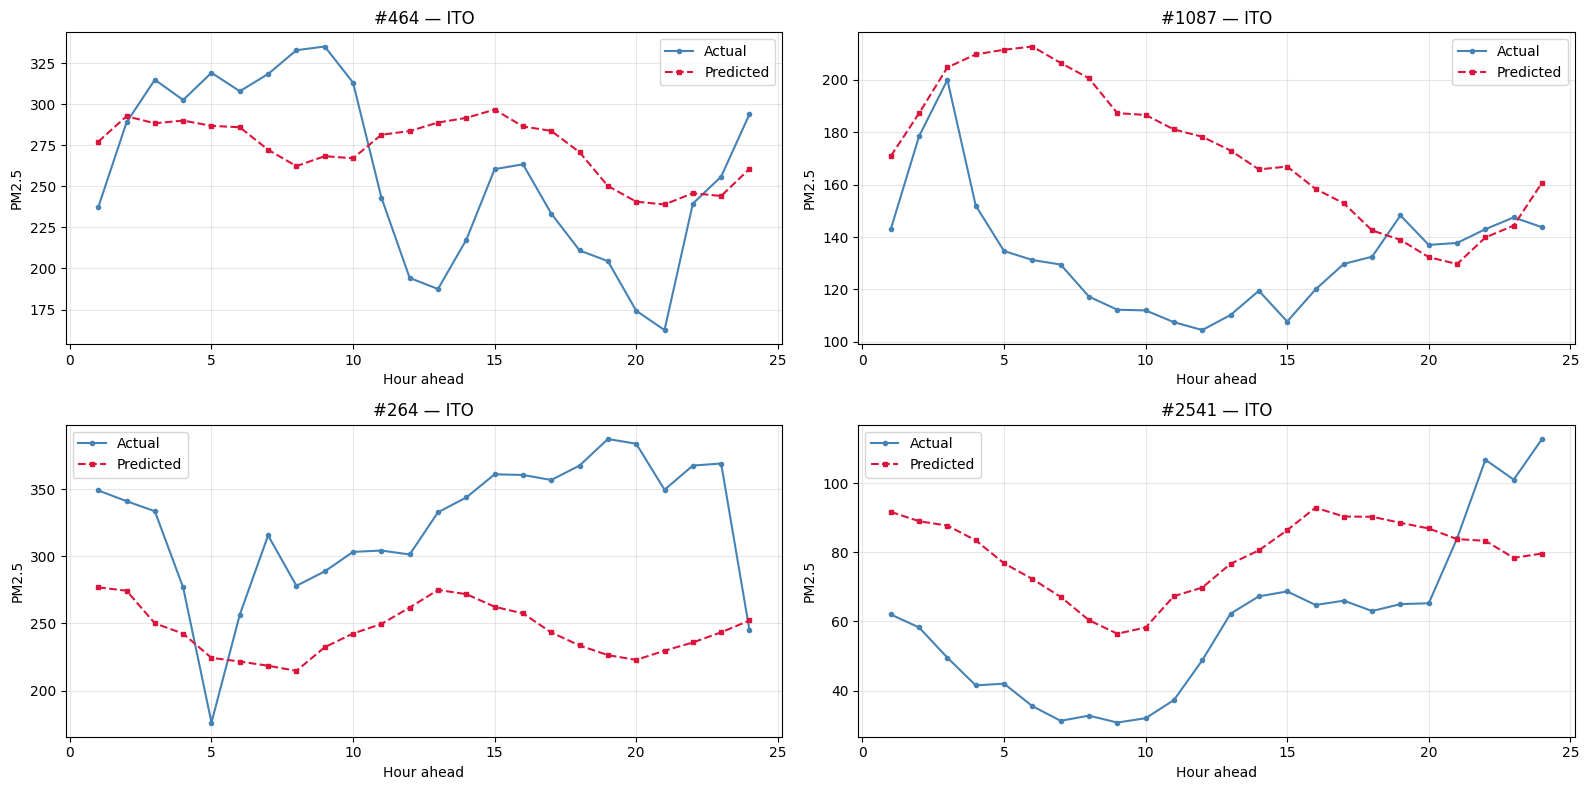

In [8]:
import pandas as pd
df_st = pd.read_excel(os.path.join(V2_DIR,'Delhi_list_v2.xlsx'))
df_st.columns = df_st.columns.str.strip().str.lower()
names = df_st['station'].str.strip().tolist()

fig, axes = plt.subplots(2,2, figsize=(16,8))
idxs = np.random.choice(preds.shape[0], 4, replace=False)
sti = 0
for ax, i in zip(axes.flat, idxs):
    ax.plot(range(1,25), actual[i,:,sti], marker='o', ms=3, color='steelblue', label='Actual')
    ax.plot(range(1,25), preds[i,:,sti], marker='s', ms=3, color='crimson', ls='--', label='Predicted')
    ax.set_title(f'#{i} — {names[sti]}'); ax.set_xlabel('Hour ahead'); ax.set_ylabel('PM2.5')
    ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR,'pred_vs_actual.png'), dpi=150, bbox_inches='tight')
plt.show()

In [9]:
rows = []
for n in range(preds.shape[2]):
    a, p = actual[:,:,n].flatten(), preds[:,:,n].flatten()
    rows.append({'Station': names[n] if n < len(names) else f'S{n}',
                 'RMSE': round(np.sqrt(mean_squared_error(a,p)),2),
                 'MAE':  round(mean_absolute_error(a,p),2),
                 'R2':   round(r2_score(a,p),4)})
ps = pd.DataFrame(rows).sort_values('RMSE')
print(ps.to_string(index=False))
ps.to_csv(os.path.join(RESULTS_DIR,'watgcn_per_station.csv'), index=False)

with open(os.path.join(RESULTS_DIR,'watgcn_overall.json'),'w') as f:
    json.dump({'model':'WA-TGCN centralised','rmse':round(rmse,4),
               'mae':round(mae,4),'r2':round(r2,4),
               'best_epoch':best_ep,'best_val_loss':round(best_val,6)}, f, indent=2)

print(f"\nOverall — RMSE {rmse:.2f} | MAE {mae:.2f} | R² {r2:.4f}")

                           Station  RMSE   MAE     R2
                        Lodhi Road 46.88 34.85 0.4792
                         Aya Nagar 47.53 34.47 0.3580
                Sri Aurobindo Marg 48.29 35.32 0.5367
                  IGI Airport (T3) 48.52 37.07 0.3430
                         Najafgarh 52.32 38.42 0.3872
Major Dhyan Chand National Stadium 53.37 41.41 0.5919
                         Pusa DPCC 54.34 41.10 0.5803
                         Pusa IITM 55.33 43.19 0.4964
                            Alipur 57.30 43.06 0.4946
          Jawaharlal Nehru Stadium 57.51 42.59 0.6103
                 CRRI Mathura Road 58.12 42.96 0.4552
                          Sirifort 58.95 40.41 0.6288
                       Mandir Marg 59.70 44.78 0.4151
                       NSIT Dwarka 59.82 42.23 0.1738
                          Shadipur 59.88 44.93 0.2936
    Dr. Karni Singh Shooting Range 60.41 43.15 0.5934
                     Chandni Chowk 61.52 43.84 0.6233
                   Dwarka-Se